# 13 · Entropy, cross-entropy and KL: forward vs reverse KL on a two-mode policy

In [1]:
import numpy as np, torch, matplotlib.pyplot as plt

def entropy(p):
    p = p[p > 0]
    return float(-(p * np.log(p)).sum()) + 0.0

def kl_gauss(m1, s1, m2, s2):
    return np.log(s2 / s1) + (s1**2 + (m1 - m2) ** 2) / (2 * s2**2) - 0.5

def bimodal_logpdf(x):
    comp = torch.stack([torch.distributions.Normal(-2.0, 0.5).log_prob(x), torch.distributions.Normal(2.0, 0.5).log_prob(x)])
    return torch.logsumexp(comp, 0) + np.log(0.5)

def fit_gaussian(direction, steps=3000, init_mu=0.5, init_log_s=0.0):
    mu = torch.tensor(init_mu, requires_grad=True)
    log_s = torch.tensor(init_log_s, requires_grad=True)
    opt = torch.optim.Adam([mu, log_s], lr=0.02)
    for _ in range(steps):
        q = torch.distributions.Normal(mu, log_s.exp())
        if direction == "forward":
            x = torch.cat([torch.randn(256) * 0.5 - 2, torch.randn(256) * 0.5 + 2])
            loss = -q.log_prob(x).mean()
        else:
            x = q.rsample((512,))
            loss = (q.log_prob(x) - bimodal_logpdf(x)).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return mu.item(), log_s.exp().item()

In [2]:
for name, p in {"one-hot (certain)": np.array([1, 0, 0, 0.]), "peaked": np.array([0.7, 0.1, 0.1, 0.1]), "uniform": np.full(4, 0.25)}.items():
    print(f"{name:18s} H = {entropy(p):.3f} nats   (max for 4 outcomes = {np.log(4):.3f})")

one-hot (certain)  H = 0.000 nats   (max for 4 outcomes = 1.386)
peaked             H = 0.940 nats   (max for 4 outcomes = 1.386)
uniform            H = 1.386 nats   (max for 4 outcomes = 1.386)


In [3]:
p = np.array([0.6, 0.3, 0.1]); q = np.array([0.4, 0.4, 0.2])
H_pq = -(p * np.log(q)).sum()
print(f"cross-entropy H(p,q) = {H_pq:.4f} = H(p) + KL(p||q) = {entropy(p):.4f} + {(p * np.log(p / q)).sum():.4f}")
print(f"KL(p||q) = {(p * np.log(p / q)).sum():.4f}   KL(q||p) = {(q * np.log(q / p)).sum():.4f}   (not symmetric)")

cross-entropy H(p,q) = 0.9856 = H(p) + KL(p||q) = 0.8979 + 0.0877
KL(p||q) = 0.0877   KL(q||p) = 0.0915   (not symmetric)


In [4]:
rng = np.random.default_rng(0)
xs = rng.normal(0.2, 1.0, 200000)
mc = np.mean(np.log(1.5) - (xs - 0.2) ** 2 / 2 + (xs - 1.0) ** 2 / (2 * 1.5**2))
print(f"KL(N(0.2,1) || N(1,1.5²)): closed form {kl_gauss(0.2, 1, 1.0, 1.5):.4f}, Monte Carlo {mc:.4f}")

KL(N(0.2,1) || N(1,1.5²)): closed form 0.2699, Monte Carlo 0.2692


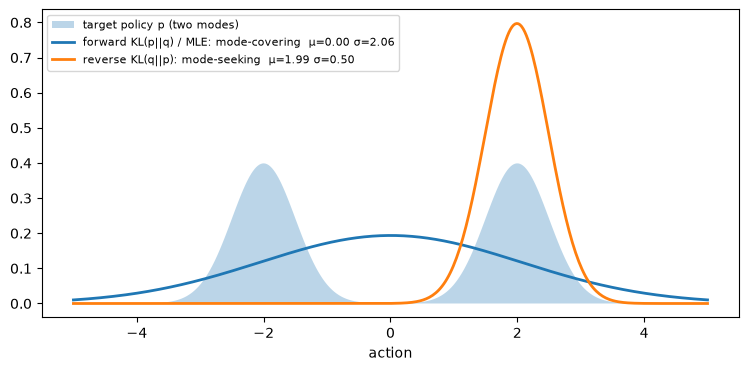

In [5]:
fwd = fit_gaussian("forward")
rev = fit_gaussian("reverse", init_mu=1.0, init_log_s=-1.0)
xs = torch.linspace(-5, 5, 400)
plt.figure(figsize=(9, 4))
plt.fill_between(xs, bimodal_logpdf(xs).exp(), alpha=0.3, label="target policy p (two modes)")
plt.plot(xs, torch.distributions.Normal(*fwd).log_prob(xs).exp(), lw=2, label=f"forward KL(p||q) / MLE: mode-covering  μ={fwd[0]:.2f} σ={fwd[1]:.2f}")
plt.plot(xs, torch.distributions.Normal(*rev).log_prob(xs).exp(), lw=2, label=f"reverse KL(q||p): mode-seeking  μ={rev[0]:.2f} σ={rev[1]:.2f}")
plt.legend(fontsize=8); plt.xlabel("action"); plt.show()